# Sowing Success: Choosing the Best Crop from Soil Measures

![Farmer in a field](farmer_in_a_field.jpg)

This notebook predicts which crop suits a field from four soil measures, and finds the single measure that predicts the crop best. It started as a DataCamp project, and I extended it by exploring how each measure varies between crops, checking the result with cross-validation, and comparing three models that use all four measures.

**A note on AI use:** The code, the analysis, and the conclusions are my own work. I used AI (Claude) as a writing aid, to help me phrase my findings clearly and to tidy the notebook's formatting and comments.

## Context

Measuring soil metrics such as nitrogen, phosphorous, potassium and pH helps to choose the right crop, but each measure costs time and money, so farmers often have to choose which ones to pay for. Each crop has an ideal soil condition that gives the best yield.

A farmer wants to know which crop to plant, and which measure is the most useful if only one can be afforded. The data is stored in `data/soil_measures.csv`. Each row is a field, and `crop` is the best crop for that field.

| Column | Description |
| --- | --- |
| `N` | Nitrogen content ratio in the soil |
| `P` | Phosphorous content ratio in the soil |
| `K` | Potassium content ratio in the soil |
| `ph` | pH value of the soil |
| `crop` | Best crop for the field (the target) |

## Goal

Find the single feature that predicts `crop` best, and save it in a dictionary called `best_predictive_feature`, with the feature name as key and its score as value.

This is a **multi-class classification** problem: the model has to choose one crop out of several. I use the **weighted F1-score** as metric. The F1-score combines precision and recall for each crop, and "weighted" averages it over all the crops.

## Plan

1. Setup
2. Load and inspect the data
3. Explore the data
4. Split the data
5. Evaluate each feature on its own
6. Use models using all four features
7. Check the best model
8. Conclusion

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics

RANDOM_STATE = 13  # makes the split, the folds and the tree reproducible
TEST_SIZE = 0.3  # 30% of the fields go to the test set
CV_FOLDS = 5  # number of folds for cross-validation
FEATURES = ["N", "P", "K", "ph"]  # the four soil measures

BLUE = "#2a78d6"  # main colour of the figures
ORANGE = "#eb6834"  # colour used to highlight

## 2. Load and inspect the data

In [2]:
crops = pd.read_csv("data/soil_measures.csv")
crops.head()

,N,P,K,ph,crop
0,90,42,43,6.502985,rice
1,85,58,41,7.038096,rice
2,60,55,44,7.840207,rice
3,74,35,40,6.980401,rice
4,78,42,42,7.628473,rice


In [3]:
crops.info()

<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   N       2200 non-null   int64  
 1   P       2200 non-null   int64  
 2   K       2200 non-null   int64  
 3   ph      2200 non-null   float64
 4   crop    2200 non-null   str    
dtypes: float64(1), int64(3), str(1)
memory usage: 101.4 KB


In [4]:
print("Missing values:", crops.isna().sum().sum())
print("Duplicated rows:", crops.duplicated().sum())
print("Number of crops:", crops["crop"].nunique())
print("Fields per crop:", crops["crop"].value_counts().unique())  # list of the different counts per crop

Missing values: 0
Duplicated rows: 0
Number of crops: 22
Fields per crop: [100]


The dataset has 2,200 fields and 5 columns, with no missing values and no duplicated rows, so there is nothing to clean. There are 22 crops with exactly 100 fields each: the classes are perfectly balanced, so no crop dominates the scores.

## 3. Explore the data

In [5]:
crops[FEATURES].describe().round(2)  # summary statistics of the four soil measures

,N,P,K,ph
count,2200.00,2200.00,2200.00,2200.00
mean,50.55,53.36,48.15,6.47
std,36.92,32.99,50.65,0.77
min,0.00,5.00,5.00,3.50
25%,21.00,28.00,20.00,5.97
50%,37.00,51.00,32.00,6.43
75%,84.25,68.00,49.00,6.92
max,140.00,145.00,205.00,9.94


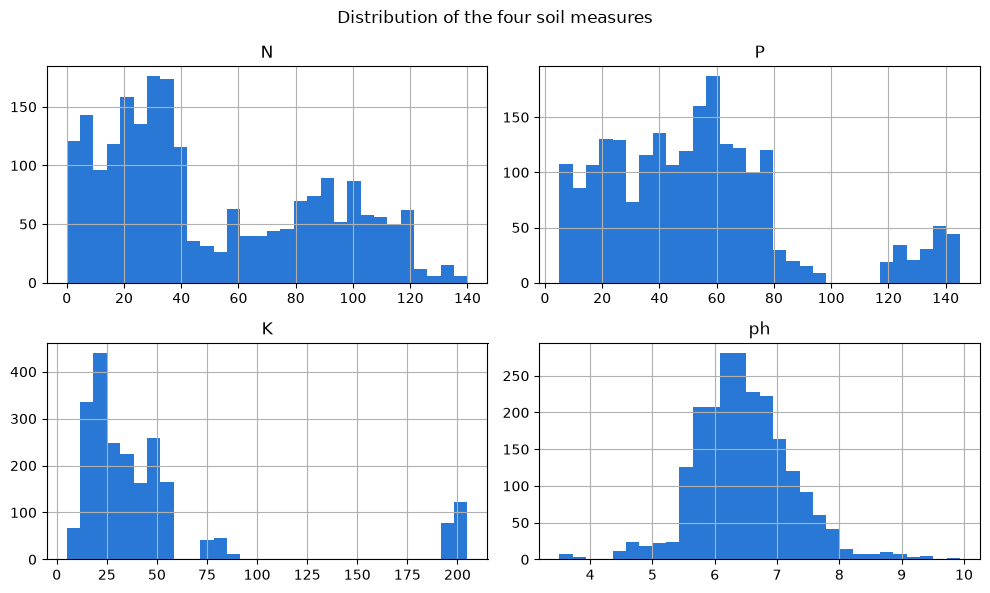

In [6]:
crops[FEATURES].hist(bins=30, figsize=(10, 6), color=BLUE)  # one histogram per soil measure
plt.suptitle("Distribution of the four soil measures")
plt.tight_layout()
plt.show()

- The measures are on different scales: `K` goes up to 205, while `ph` stays between 3.5 and 9.9.
- `N`, `P` and `K` are not bell-shaped: they have several groups of values, with separate groups at high values for `P` (around 120–145) and `K` (around 200). These groups probably belong to specific crops.
- `ph` is the only measure with one central peak, around 6.5.

### How do the soil measures change from one crop to another?

To predict the crop, a measure must take different values for different crops. I plot each measure for each crop.

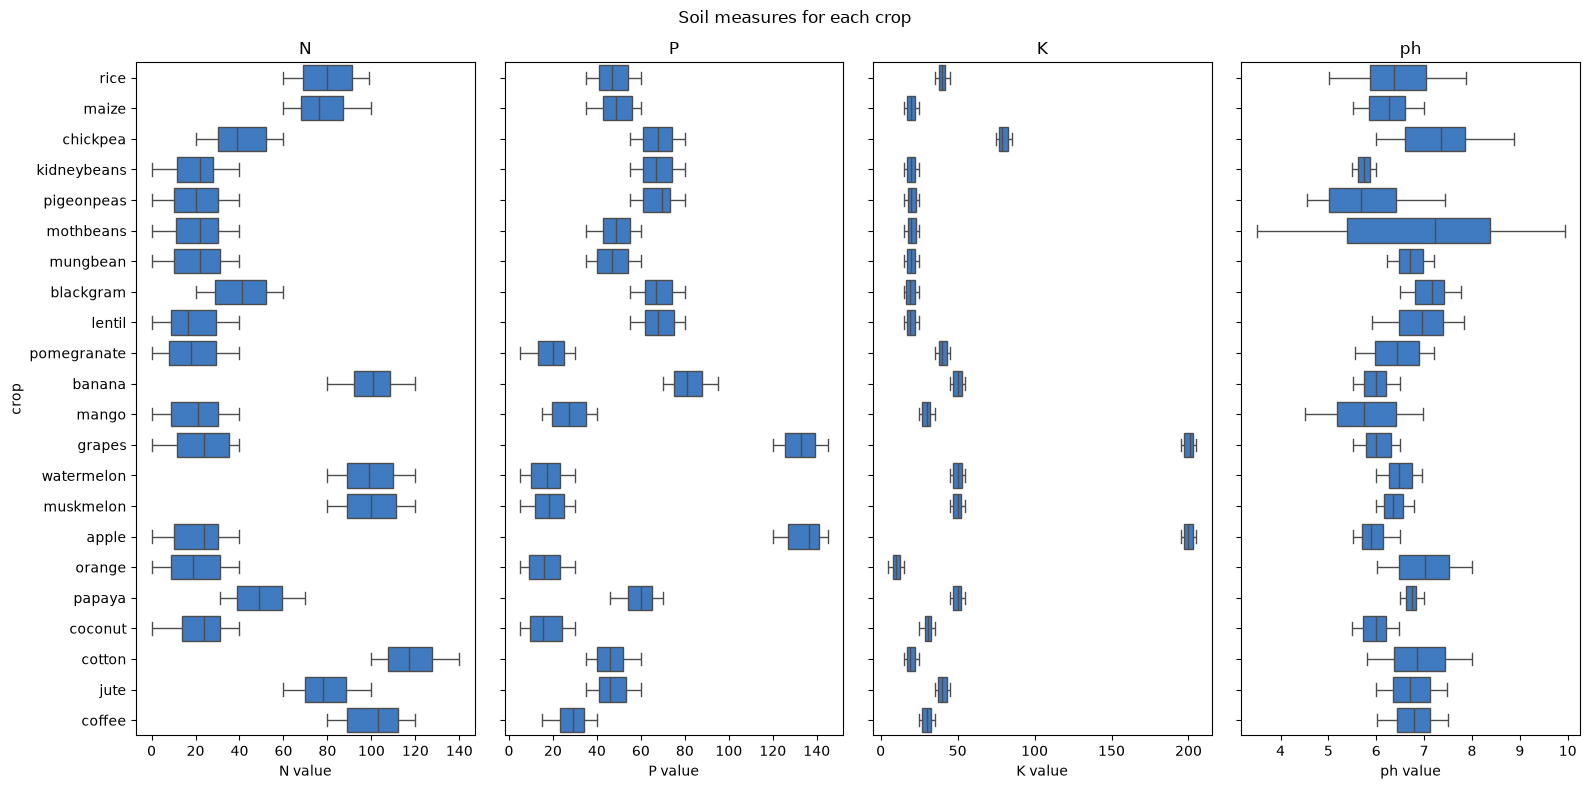

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 8), sharey=True)  # four plots side by side, sharing the list of crops

for ax, feature in zip(axes, FEATURES):  # zip pairs each plot with one soil measure
    sns.boxplot(data=crops, x=feature, y="crop", color=BLUE, ax=ax)
    ax.set_title(feature)
    ax.set_xlabel(f"{feature} value")
    ax.set_ylabel("crop")

plt.suptitle("Soil measures for each crop")
plt.tight_layout()
plt.show()

Here:

- `K` separates a few crops very clearly: 
  - grapes and apple are the only ones around 200
  - chickpea is alone around 80
  - most other crops overlap between 10 and 55
  
- `P` also isolates grapes and apple (around 120–145)
  
- `N` splits the crops into a low group (below 60) and a high group (cotton, banana, watermelon, muskmelon, coffee, etc.)
  
- `ph` varies a lot inside each crop and overlaps between crops, so it should be the weakest predictor
  
- Some crops have almost the same profile on all four measures, for example apple and grapes, or watermelon and muskmelon.

Correlation between the soil measures:
        N     P     K    ph
N   1.00 -0.23 -0.14  0.10
P  -0.23  1.00  0.74 -0.14
K  -0.14  0.74  1.00 -0.17
ph  0.10 -0.14 -0.17  1.00


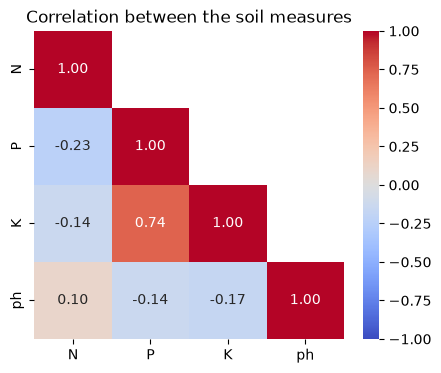

In [8]:
correlation = crops[FEATURES].corr().round(2) # correlation between the different soil measures
print("Correlation between the soil measures:\n", correlation)

mask = np.triu(np.ones_like(correlation, dtype=bool), k=1)  # set a mask to hide the upper triangle of the correlation matrix

plt.figure(figsize=(5, 4))
sns.heatmap(correlation, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between the soil measures")
plt.show()

I can notice here that:
- `P` and `K` are strongly correlated (0.74) which means that fields with a lot of phosphorous often have a lot of potassium. 
- The other correlations are weaker (between -0.23 and 0.10).

## 4. Split the data


In [9]:
X = crops[FEATURES]  # the four soil measures
y = crops["crop"]  # the crop to predict

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y  # with stratify each crop keeps the same share in the train and test sets.
)

print("Train set:", X_train.shape)
print("Test set:", X_test.shape)
print("Fields per crop in the train set:", y_train.value_counts().unique())
print("Fields per crop in the test set:", y_test.value_counts().unique())

Train set: (1540, 4)
Test set: (660, 4)
Fields per crop in the train set: [70]
Fields per crop in the test set: [30]


## 5. Evaluate each feature on its own

For each feature, I train a logistic regression that only sees this feature, and I compute its weighted F1-score on the test set. 

Logistic regression is sensitive to the scale of the data, so I use a `Pipeline` with a `StandardScaler`

In [10]:
features_dict = {}  # F1-score of each feature on its own

for feature in FEATURES:
    logreg = Pipeline([
        ("scaler", StandardScaler()),  # instantiate the scaler to standardize the feature
        ("logreg", LogisticRegression(max_iter=1000)),  # instantiate logistic regression with more iterations so the model can finish learning
    ])

    logreg.fit(X_train[[feature]], y_train)  # double brackets keep X as a table with one column
    y_pred = logreg.predict(X_test[[feature]])

    feature_performance = metrics.f1_score(y_test, y_pred, average="weighted")  # averaged F1 score for each crop
    features_dict[feature] = feature_performance
    print(f"F1-score for {feature}: {feature_performance:.3f}")

F1-score for N: 0.112
F1-score for P: 0.172
F1-score for K: 0.219
F1-score for ph: 0.081


In [11]:
best_feature = max(features_dict, key=features_dict.get)  # the key with the highest value in the dictionary
best_predictive_feature = {best_feature: features_dict[best_feature]}

print(best_predictive_feature)

{'K': 0.21915314283676945}


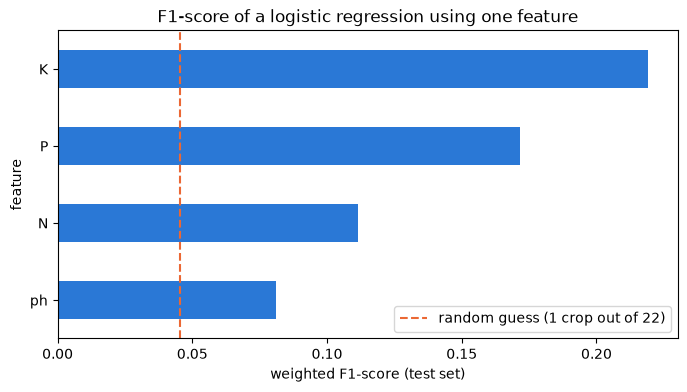

In [12]:
pd.Series(features_dict).sort_values().plot(kind="barh", color=BLUE, figsize=(8, 4))

plt.axvline(1 / 22, color=ORANGE, linestyle="--", label="random guess (1 crop out of 22)")
plt.title("F1-score of a logistic regression using one feature")
plt.xlabel("weighted F1-score (test set)")
plt.ylabel("feature")
plt.legend()
plt.show()

- `K` gives the best F1-score (0.219), followed by `P` (0.172), `N` (0.112) and `ph` (0.081). This matches the boxplots: `K` isolates a few crops very clearly, and `ph` overlaps the most.
- So `best_predictive_feature` is `{'K': 0.219}`.
- All four scores are above a random guess (about 0.045 with 22 crops), but even the best one is low: one measure alone is not enough to choose the right crop.

### Is the result stable?

The score above comes from one test set. To check that the ranking does not depend on this particular split, I repeat the evaluation with 5-fold cross-validation on the train set.

In [13]:
kf = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)  # the same 5 folds for every model

single_feature_cv = {}

for feature in FEATURES:
    logreg = Pipeline([("scaler", StandardScaler()), ("logreg", LogisticRegression(max_iter=1000))])

    cv_scores = cross_val_score(logreg, X_train[[feature]], y_train, cv=kf, scoring="f1_weighted")  # one F1-score per fold
    single_feature_cv[feature] = [cv_scores.mean(), cv_scores.std()]

pd.DataFrame(single_feature_cv, index=["mean CV F1", "std CV F1"]).T.round(3)  # .T transposes so features are rows

,mean CV F1,std CV F1
N,0.071,0.017
P,0.103,0.017
K,0.130,0.010
ph,0.034,0.005


The cross-validation scores are lower than the test scores (0.130 for `K` instead of 0.219), so the test set was a bit favourable. But the **ranking is the same** (`K`, `P`, `N`, `ph`) and the spread between folds is small, so `K` really is the best single feature.

## 6. Extension: models using all four features

One feature alone gives a weak prediction. I now give the four features to three supervised learning models and compare them with cross-validation, before any tuning:
- **Logistic regression**, a linear model,
- **KNN**, which predicts the crop of the closest fields,
- **a decision tree**, which asks a series of questions on the features.

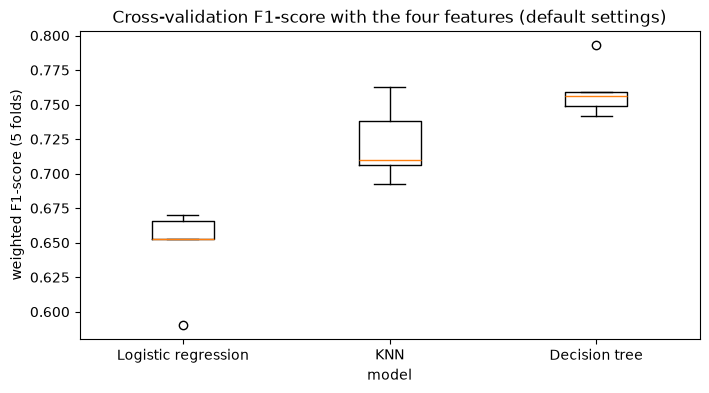

Logistic regression: mean CV F1 = 0.646
KNN: mean CV F1 = 0.722
Decision tree: mean CV F1 = 0.760


In [14]:
models = {
    "Logistic regression": Pipeline([("scaler", StandardScaler()), ("logreg", LogisticRegression(max_iter=1000))]),
    "KNN": Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())]),  # KNN uses distances, so it needs scaling
    "Decision tree": DecisionTreeClassifier(random_state=RANDOM_STATE),  # a tree does not need scaling
}

cv_results = []
for model in models.values(): # loop through the models dictionary
    cv_scores = cross_val_score(model, X_train, y_train, cv=kf, scoring="f1_weighted") # one F1-score per fold
    cv_results.append(cv_scores)

plt.figure(figsize=(8, 4))
plt.boxplot(cv_results, tick_labels=models.keys())  # one box of 5 fold scores per model
plt.title("Cross-validation F1-score with the four features (default settings)")
plt.xlabel("model")
plt.ylabel("weighted F1-score (5 folds)")
plt.show()

for name, cv_scores in zip(models.keys(), cv_results): # loop through the model names and the corresponding cross-validation scores
    print(f"{name}: mean CV F1 = {cv_scores.mean():.3f}") # print the mean CV F1 score for each model

With the four features, every model is far better than with one. The mean CV F1-score is 
- 0.646 for logistic regression
- 0.722 for KNN 
- 0.760 for the decision tree 

The tree is also the most stable across the folds. The features probably interact, which a tree and KNN handle better than a linear model.

### Tuning KNN

The main setting of KNN is the number of neighbours `k`. 
- A small `k` follows the training data very closely (risk of overfitting), 
- a large `k` smooths too much (risk of underfitting). 

I will now plot the train and cross-validation F1-score for `k` from 1 to 30 neighbors, and let `GridSearchCV` pick the best value.

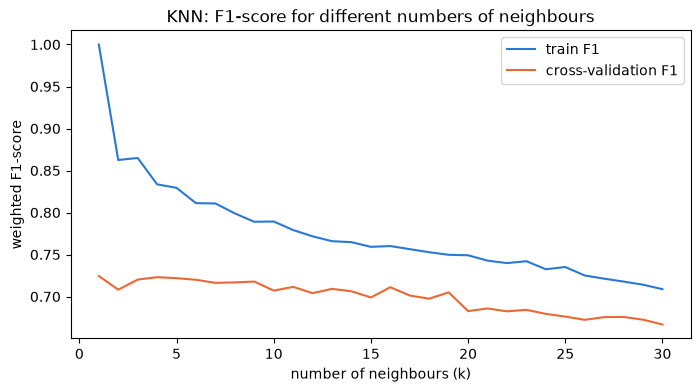

In [15]:
neighbors = np.arange(1, 31)  # number of neighbours to try
train_f1 = []
cv_f1 = []

for k in neighbors:
    knn = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=k))])

    knn_cv_scores = cross_val_score(knn, X_train, y_train, cv=kf, scoring="f1_weighted")  # fit the model on different folds and calculate one F1-score per fold
    cv_f1.append(knn_cv_scores.mean())  

    knn.fit(X_train, y_train) # fit the model on the full training set
    train_f1.append(metrics.f1_score(y_train, knn.predict(X_train), average="weighted"))  # error on the fields it has seen

plt.figure(figsize=(8, 4))
plt.plot(neighbors, train_f1, color=BLUE, label="train F1") # plot the F1-score on the training set it has seen
plt.plot(neighbors, cv_f1, color=ORANGE, label="cross-validation F1") # plot the F1-score on the unseen folds

plt.title("KNN: F1-score for different numbers of neighbours")
plt.xlabel("number of neighbours (k)")
plt.ylabel("weighted F1-score")
plt.legend()
plt.show()

In [16]:
knn_grid = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())]),
    param_grid={"knn__n_neighbors": neighbors},
    cv=kf, 
    scoring="f1_weighted"
)

knn_grid.fit(X_train, y_train)

knn_scores = pd.DataFrame({
    "k": knn_grid.cv_results_["param_knn__n_neighbors"],  # the k tried
    "mean CV F1": knn_grid.cv_results_["mean_test_score"],  # its mean F1 over the 5 folds
})
knn_scores.head(10).round(3)  # k from 1 to 10


,k,mean CV F1
0,1,0.724
1,2,0.708
2,3,0.720
3,4,0.723
4,5,0.722
5,6,0.720
6,7,0.716
7,8,0.717
8,9,0.718
9,10,0.707


- With `k = 1`, the train F1-score is 1.0: the model just remembers each training field, which is overfitting.
- The cross-validation F1-score is almost flat from `k = 1` to `k = 9` (between 0.70 and 0.73), then slowly decreases. 
- `GridSearchCV` picks `k = 1` (0.724), but a single unusual field in the train set is then enough to change a prediction.
- Since the curve is flat, a larger `k` costs almost nothing. **I choose `k = 5`** (0.722): the prediction is a vote of 5 neighbours, which is less sensitive to one odd field, for almost the same score. 

In [17]:
best_k = 5  # my choice of k, explained above
knn_final = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=best_k))])

knn_cv_f1 = cross_val_score(knn_final, X_train, y_train, cv=kf, scoring="f1_weighted").mean()  # mean F1 over the 5 folds
knn_final.fit(X_train, y_train)  # fit on the whole train set for the test later
print("CV F1 with k = 5:", round(knn_cv_f1, 3))

CV F1 with k = 5: 0.722


### Tuning the decision tree

For the tree, I tune `max_depth` (how many questions in a row) and `min_samples_leaf` (the smallest group of fields at the end of a branch).

In [18]:
param_grid = {"max_depth": [5, 10, 15, None], "min_samples_leaf": [1, 5, 10]}

tree_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid,
    cv=kf, 
    scoring="f1_weighted",
)

tree_grid.fit(X_train, y_train)

print("Best hyperparameters:", tree_grid.best_params_)
print("CV F1 with best hyperparameters:", round(tree_grid.best_score_, 3))

Best hyperparameters: {'max_depth': 10, 'min_samples_leaf': 1}
CV F1 with best hyperparameters: 0.766


The best tree has `max_depth=10` and `min_samples_leaf=1`, with a CV F1-score of 0.766, a small gain over the default tree (0.760).

## 7. Check the best model

I choose the model with the best cross-validation F1-score, then evaluate it once on the test set.

In [19]:
cv_scores_by_model = {
    "Logistic regression": cv_results[0].mean(), 
    "KNN (k = 5)": knn_cv_f1,
    "Decision tree (tuned)": tree_grid.best_score_,
}

best_model_name = max(cv_scores_by_model, key=cv_scores_by_model.get)
print("Best model on cross-validation:", best_model_name)

Best model on cross-validation: Decision tree (tuned)


In [20]:
best_model = tree_grid.best_estimator_  # the tuned tree, already refitted on the whole train set
y_pred_best = best_model.predict(X_test)

print("Test F1-score:", round(metrics.f1_score(y_test, y_pred_best, average="weighted"), 3), "\n")
print(metrics.classification_report(y_test, y_pred_best))

Test F1-score: 0.761 

              precision    recall  f1-score   support

       apple       0.41      0.43      0.42        30
      banana       1.00      1.00      1.00        30
   blackgram       1.00      0.43      0.60        30
    chickpea       1.00      1.00      1.00        30
     coconut       0.78      0.97      0.87        30
      coffee       0.94      0.97      0.95        30
      cotton       1.00      0.93      0.97        30
      grapes       0.39      0.37      0.38        30
        jute       0.58      0.73      0.65        30
 kidneybeans       0.81      1.00      0.90        30
      lentil       0.42      1.00      0.59        30
       maize       1.00      1.00      1.00        30
       mango       0.96      0.73      0.83        30
   mothbeans       0.96      0.77      0.85        30
    mungbean       0.89      0.57      0.69        30
   muskmelon       0.45      0.47      0.46        30
      orange       1.00      1.00      1.00        30
    

The tuned decision tree reaches a test F1-score of 0.761, very close to its CV score (0.766), so the cross-validation estimate was reliable.

The report shows two groups of crops:
- **Perfectly predicted** (F1 = 1.00): banana, chickpea, maize, orange and papaya. 
  - Pomegranate and cotton are close (0.98 and 0.97).
- **Badly predicted** (F1 below 0.50): grapes (0.38), apple (0.42), watermelon (0.44) and muskmelon (0.46).

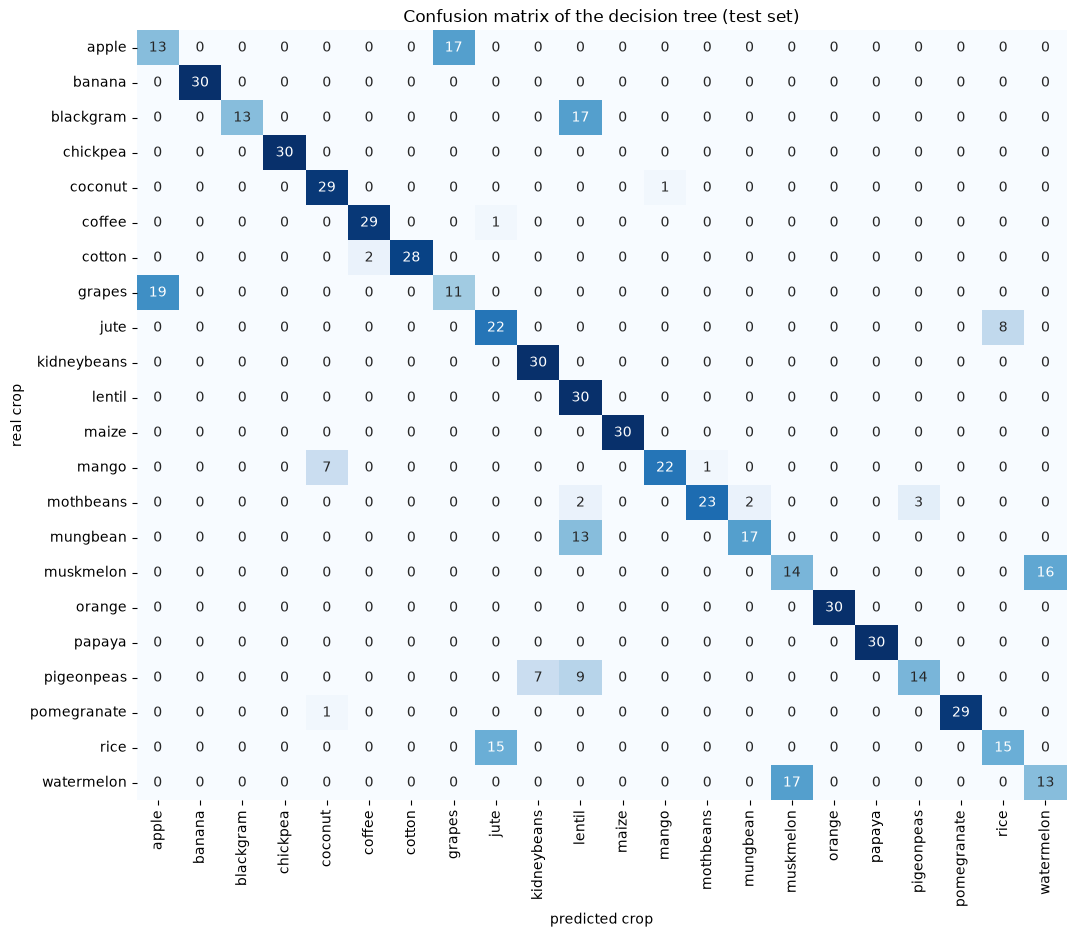

In [21]:
crop_names = sorted(y.unique())  # crops in alphabetical order, the same order as the matrix
confusion = metrics.confusion_matrix(y_test, y_pred_best, labels=crop_names)

plt.figure(figsize=(12, 10))
sns.heatmap(confusion, annot=True, cmap="Blues", cbar=False, 
            xticklabels=crop_names, yticklabels=crop_names)  # annot writes the count in each cell
plt.title("Confusion matrix of the decision tree (test set)")
plt.xlabel("predicted crop")
plt.ylabel("real crop")
plt.show()

The errors are not random: they come in **pairs of crops with the same soil profile**, as seen in the boxplots.

- Apple and grapes: 17 apple fields are predicted as grapes, and 19 grapes fields as apple.
- Watermelon and muskmelon: 17 and 16 fields confused in both directions.
- Rice is often predicted as jute (15 fields) 
- Blackgram, mungbean and pigeonpeas are often predicted as lentil (17, 13 and 9 fields).

With only these four soil measures, these crops cannot be told apart.

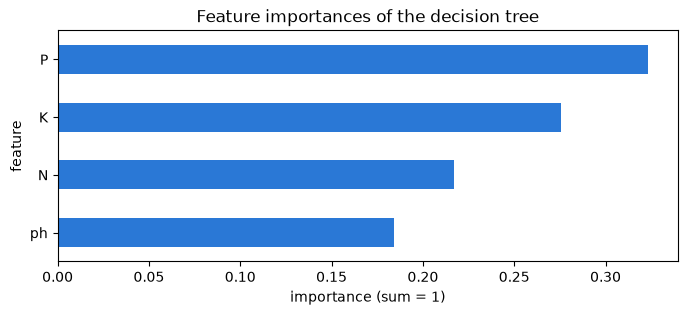

P     0.323
K     0.276
N     0.217
ph    0.184
dtype: float64

In [22]:
importances = pd.Series(best_model.feature_importances_, index=FEATURES)  # how much each feature helped the tree

importances.sort_values().plot(kind="barh", color=BLUE, figsize=(8, 3))
plt.title("Feature importances of the decision tree")
plt.xlabel("importance (sum = 1)")
plt.ylabel("feature")
plt.show()

importances.sort_values(ascending=False).round(3)

With all four features, `P` is the most used by the tree (0.323), before `K` (0.276), `N` (0.217) and `ph` (0.184). 

This is not in contradiction with what was said in section 5: `K` is the best feature **alone**, but in a tree the features work together, and `P` and `K` partly carry the same information (correlation of 0.74). 

All four features contribute.

## 8. Conclusion

**What the results show**

- **The answer to the brief:** `K` (potassium) is the single feature that predicts the crop best, with a weighted F1-score of 0.219 (`best_predictive_feature`). Cross-validation confirms the ranking `K` > `P` > `N` > `ph`.
  
- **One measure is not enough:** even the best single feature gives a weak prediction. With all four measures, the scores are three to four times higher.
  
- **The best model** is a tuned decision tree (test F1-score of 0.761), ahead of KNN with `k = 5` (0.728) and logistic regression (0.649).
  
- **Some crops cannot be separated** by soil alone: apple and grapes, watermelon and muskmelon, and rice and jute have nearly the same soil profile.

**For the farmer:** if only one measure fits the budget, it should be potassium `K`. But measuring all four gives a much more reliable recommendation, and for crops with the same soil profile, another criterion is needed to choose.